---
title: "Gravity and Orbits — Level 2"
short_title: "07 Gravity & Orbits"
numbering:
  heading_2: true
  equation: true
---

# Gravity and Orbits

:::{seealso} Math for this topic
- [M2: Coordinates, integrals and the delta function](../math/02-coordinates-integrals-delta.ipynb)
- [M4: Linear ODEs, Fourier series and transforms](../math/04-linear-odes-fourier.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 11 | Circular orbits and Kepler's laws used as given facts |
| **2** | **Taylor, ch. 8** | **Derive conic-section orbits from the orbit equation u(φ)** |
| 3 | Goldstein, ch. 3 | Two-body reduction in general, orbital stability, scattering in 1/r potentials |

The new skill at this level: deriving Kepler's laws instead of quoting them, by solving an ODE for the shape of the orbit

Math for this topic: M2 (conic sections, multiple integrals) and M4 (second-order linear ODEs).
:::

Builds on the angular momentum notes (effective potential) and the Lagrangian notes. Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [M6: Linear algebra](../math/06-linear-algebra.ipynb), the math for the next chapter. If you miss a part, study just the section it names and try that problem again.

1. **Reducing Two Bodies to One**

   (a) Two stars of mass $M$ each orbit each other in a circle, a distance $d$ apart. Find the period.

   (b) The Moon's mass is $1/81$ of Earth's, and the two are $3.84\times10^5$ km apart. How far from Earth's center is their center of mass? Is it inside the Earth ($R_\oplus = 6.37\times10^3$ km)?

2. **The Orbit Equation**

   The orbit equation is $u'' + u = -\dfrac{\mu}{\ell^2u^2}F(1/u)$, with $u = 1/r$. Find the orbits for $F = -k/r^3$. What happens when $\mu k > \ell^2$?

3. **The Kepler Orbits**

   (a) Mars has $a = 1.52$ AU. Find its period in years.

   (b) A comet has perihelion 1 AU and aphelion 3 AU. Find $a$, $e$ and its period.

   (c) What does the sign of the total energy tell you about the orbit's shape?

4. **Changing Orbits**

   A Hohmann transfer takes a satellite from a circular orbit of radius $r_1$ to one of radius $4r_1$. Use $v^2 = GM(2/r - 1/a)$.

   (a) Find both speed changes as fractions of the initial circular speed $v_1$.

   (b) Find the transfer time as a multiple of the initial orbital period.

5. **When Orbits Do Not Close**

   (a) Which power-law forces make every bound orbit close?

   (b) A small extra force makes the effective power law slightly steeper than $1/r^2$. Does the perihelion advance or regress?

6. **Gravity of Extended Bodies**

   (a) Find $g$ at a depth $R/2$ inside a uniform-density planet, as a fraction of its surface value.

   (b) Find the gravitational potential at the center of a uniform ball of mass $M$ and radius $R$.

:::{dropdown} Answers
1. (a) $\tau^2 = \dfrac{4\pi^2d^3}{G(2M)}$, so $\tau = 2\pi\sqrt{d^3/(2GM)}$.

   (b) $d/82 \approx 4.7\times10^3$ km. That is inside the Earth.

2. $u'' + \left(1 - \mu k/\ell^2\right)u = 0$. For $\mu k < \ell^2$, $u$ oscillates in $\phi$ with a period longer than $2\pi$, so the orbit precesses (or the particle escapes). For $\mu k > \ell^2$, $u$ grows exponentially and the particle spirals into the center.

3. (a) $1.52^{3/2} \approx 1.87$ years.

   (b) $a = 2$ AU, $e = (3 - 1)/(3 + 1) = 0.5$, and $\tau = 2^{3/2} \approx 2.83$ years.

   (c) $E < 0$ gives an ellipse (or circle), $E = 0$ a parabola, and $E > 0$ a hyperbola.

4. (a) The transfer orbit has $a = 2.5r_1$. At $r_1$, $v = \sqrt{1.6}\,v_1 \approx 1.265v_1$, so $\Delta v_1 \approx 0.265v_1$. At $4r_1$, $v = \sqrt{0.1}\,v_1 \approx 0.316v_1$, and the circular speed there is $0.5v_1$, so $\Delta v_2 \approx 0.184v_1$.

   (b) Half the transfer period: $\tfrac12(2.5)^{3/2} \approx 1.98$ times the initial period.

5. (a) Only the inverse-square force and the linear (Hooke) force (Bertrand's theorem).

   (b) The apsidal angle $\pi/\sqrt{n + 3}$ exceeds $\pi$ when $n < -2$, so the perihelion advances.

6. (a) Inside a uniform ball, $g \propto r$, so $g/2$.

   (b) $-\dfrac{3GM}{2R}$.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## Reducing Two Bodies to One

Two bodies interacting through a central force $U(r)$, with $\vec{r} = \vec{r}_1 - \vec{r}_2$, have

$$
\mathcal{L} = \tfrac12M\dot{\vec{R}}^2 + \tfrac12\mu\dot{\vec{r}}^2 - U(r), \qquad M = m_1 + m_2,\quad \mu = \frac{m_1m_2}{m_1 + m_2} .
$$

The center of mass $\vec{R}$ is cyclic, so it moves uniformly. The relative coordinate behaves like a **single particle of mass $\mu$** in the potential $U(r)$. In the planar polar coordinates of the orbit,

$$
\mathcal{L}_{\text{rel}} = \tfrac12\mu\left(\dot r^2 + r^2\dot\phi^2\right) - U(r) ,
$$

with $\phi$ cyclic, so $\ell = \mu r^2\dot\phi$ is conserved. When one body is much heavier (the Sun and a planet), $\mu$ is almost the light body's mass and the heavy one barely moves.

## The Orbit Equation

The effective potential (angular momentum notes) gives $r(t)$, but the **shape** $r(\phi)$ is usually what we want. Two tricks make it simple:

1. Use $\phi$ instead of $t$ as the variable: $\frac{d}{dt} = \dot\phi\frac{d}{d\phi} = \frac{\ell}{\mu r^2}\frac{d}{d\phi}$.
2. Use $u = 1/r$ instead of $r$.

Substituting into the radial equation $\mu(\ddot r - r\dot\phi^2) = F(r)$ gives the **orbit equation**:

$$
u''(\phi) + u(\phi) = -\frac{\mu}{\ell^2u^2}\,F\!\left(\frac1u\right) .
$$ (eq-orbit)

In [2]:
# Verify the orbit-equation substitution with sympy
phi = sp.symbols("phi")
mu, l = sp.symbols("mu ell", positive=True)
u = sp.Function("u")(phi)
r = 1 / u
phidot = l * u**2 / mu                       # from ell = mu r^2 phidot
rdot = sp.diff(r, phi) * phidot
rddot = sp.diff(rdot, phi) * phidot
lhs = sp.simplify(mu * (rddot - r * phidot**2))   # = F(r)
display(Math(r"\mu\left(\ddot r - r\dot\phi^2\right) = " + sp.latex(sp.factor(lhs))))
# This equals F, so  -(ell^2 u^2 / mu)(u'' + u) = F,  which rearranges to the orbit equation.

<IPython.core.display.Math object>

## The Kepler Orbits

For gravity, $F = -\gamma/r^2 = -\gamma u^2$ with $\gamma = Gm_1m_2$. The right side of {eq}`eq-orbit` becomes the **constant** $\gamma\mu/\ell^2$, so the orbit equation is the simplest possible linear ODE:

$$
u'' + u = \frac{\gamma\mu}{\ell^2} .
$$

The general solution (M4) is a constant particular solution plus a sinusoid. Choosing $\phi = 0$ at closest approach,

$$
u = \frac{\gamma\mu}{\ell^2}\big(1 + \epsilon\cos\phi\big) \quad\Longrightarrow\quad r(\phi) = \frac{c}{1 + \epsilon\cos\phi}, \qquad c = \frac{\ell^2}{\gamma\mu} .
$$ (eq-kepler-orbit)

This is exactly the conic section from M2, with the force center at a focus. **Kepler's first law** is derived, not assumed.

### Energy and eccentricity

Evaluating the energy at closest approach ($\dot r = 0$) relates the shape to the energy:

$$
E = \frac{\gamma^2\mu}{2\ell^2}\left(\epsilon^2 - 1\right) .
$$ (eq-energy-ecc)

| Energy | Eccentricity | Orbit |
|---|---|---|
| $E = -\gamma^2\mu/2\ell^2$ (minimum) | $\epsilon = 0$ | circle |
| $E < 0$ | $0 < \epsilon < 1$ | ellipse |
| $E = 0$ | $\epsilon = 1$ | parabola (just escapes) |
| $E > 0$ | $\epsilon > 1$ | hyperbola |

For an ellipse, the semi-major axis depends **only on the energy**: $a = c/(1 - \epsilon^2) = \gamma/(2|E|)$.

### Kepler's third law

The area of the ellipse is $\pi ab$, and Kepler's second law says area is swept at rate $\ell/2\mu$. So the period is $\tau = 2\pi ab\mu/\ell$. Using $b = a\sqrt{1 - \epsilon^2}$ and $c = \ell^2/(\gamma\mu)$,

$$
\tau^2 = \frac{4\pi^2}{G(m_1 + m_2)}\,a^3 .
$$ (eq-kepler3)

The $m_1 + m_2$ (rather than just the Sun's mass) is a small correction that the two-body reduction gets right. It is how binary-star masses are measured.

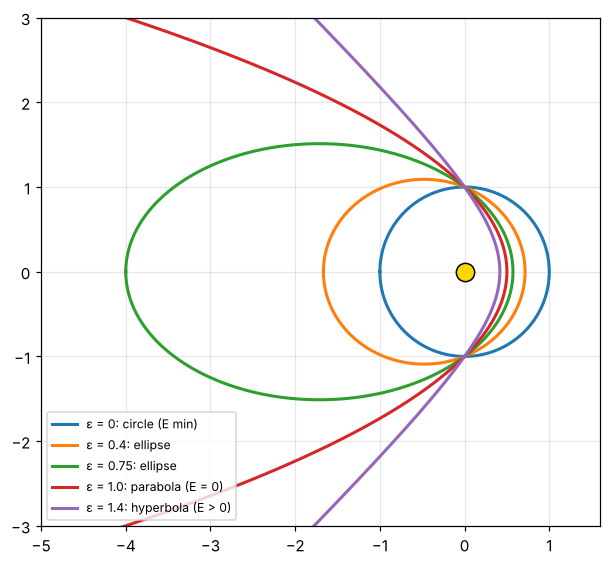

In [3]:
#| label: fig-kepler-family
#| caption: Orbits with the same angular momentum and different energies, all sharing the focus at the origin. Raising the energy stretches the ellipse until it opens into a parabola (E = 0) and then a hyperbola.
fig, ax = plt.subplots(figsize=(7.5, 6))
c = 1.0
for eps, lab in [(0, "circle (E min)"), (0.4, "ellipse"), (0.75, "ellipse"), (1.0, "parabola (E = 0)"), (1.4, "hyperbola (E > 0)")]:
    ph = np.linspace(-np.pi, np.pi, 4000)
    den = 1 + eps * np.cos(ph)
    ok = den > 0.02
    r = np.where(ok, c / np.where(ok, den, 1), np.nan)
    ax.plot(r * np.cos(ph), r * np.sin(ph), lw=2, label=f"ε = {eps}: {lab}")
ax.plot(0, 0, "o", color="gold", ms=12, mec="k")
ax.set_xlim(-5, 1.6); ax.set_ylim(-3, 3); ax.set_aspect("equal"); ax.legend(fontsize=8, loc="lower left")
plt.show()

### Exercises

1. Find the radius of a geostationary orbit ($\tau$ = one sidereal day, 86 164 s). Use $GM_\oplus = 3.986\times10^{14}$ m³/s².
2. Show from {eq}`eq-energy-ecc` that the circular orbit has the lowest energy for a given $\ell$, and that it matches the minimum of $U_{\text{eff}}$.
3. Find the escape speed from Earth's surface ($R_\oplus = 6.37\times10^6$ m).

:::{dropdown} Hints
1. Use {eq}`eq-kepler3` with $a = r$ and $m_{\text{sat}}\ll M_\oplus$.
2. $\epsilon^2\ge0$. For the second part, minimize $\ell^2/(2\mu r^2) - \gamma/r$.
3. Escape means $E = 0$.
:::

:::{dropdown} Answers
1. $r = (GM\tau^2/4\pi^2)^{1/3}\approx4.22\times10^7$ m, about 35 800 km above the surface.
2. $E\ge-\gamma^2\mu/2\ell^2$ with equality at $\epsilon = 0$. $U_{\text{eff}}$ is minimized at $r_0 = \ell^2/(\gamma\mu) = c$, where $U_{\text{eff}} = -\gamma^2\mu/2\ell^2$.
3. $v = \sqrt{2GM/R}\approx11.2$ km/s.
:::

## Changing Orbits

Rewriting the energy of an orbit in terms of $a$ gives the **vis-viva equation**, the speed anywhere on a Kepler orbit:

$$
v^2 = GM\left(\frac2r - \frac1a\right) .
$$ (eq-vis-viva)

A short engine burn changes $v$ at one point without changing $r$, so it changes $a$ and hence the whole orbit. The cheapest two-burn route between two circular orbits of radii $r_1 < r_2$ is the **Hohmann transfer**: an ellipse touching both circles, with $a_t = (r_1 + r_2)/2$.

1. At $r_1$, speed up from the circular speed $\sqrt{GM/r_1}$ to the transfer ellipse's perihelion speed.
2. Coast half an ellipse.
3. At $r_2$, speed up again from the aphelion speed to the circular speed $\sqrt{GM/r_2}$.

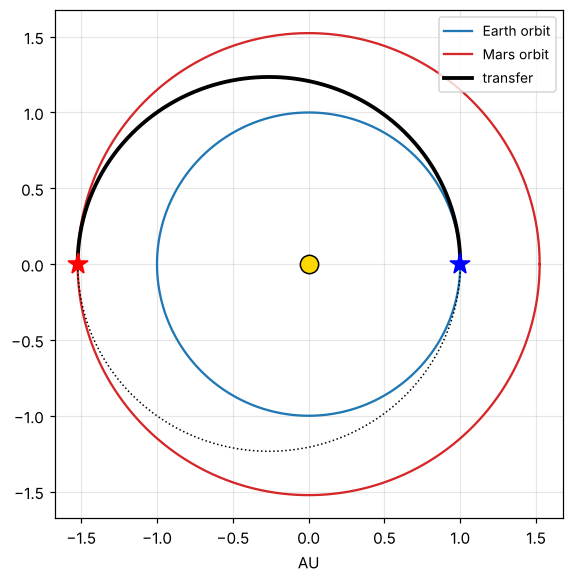

burn 1: 2.94 km/s, burn 2: 2.65 km/s, transfer time 259 days


In [4]:
#| label: fig-hohmann
#| caption: A Hohmann transfer from Earth's orbit to Mars's (circular-orbit approximation). The burns happen at perihelion and aphelion of the transfer ellipse, half an orbit apart.
GM = 1.327e20                      # Sun, m^3/s^2
r1, r2 = 1.496e11, 2.279e11        # mean orbital radii of Earth and Mars, m
at = (r1 + r2) / 2
v1c, v2c = np.sqrt(GM / r1), np.sqrt(GM / r2)
vp, va = np.sqrt(GM * (2 / r1 - 1 / at)), np.sqrt(GM * (2 / r2 - 1 / at))
dv1, dv2 = vp - v1c, v2c - va
t_transfer = np.pi * np.sqrt(at**3 / GM)

ph = np.linspace(0, 2 * np.pi, 400)
e = (r2 - r1) / (r1 + r2)
rt = at * (1 - e**2) / (1 + e * np.cos(ph))
AU = 1.496e11
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(r1 / AU * np.cos(ph), r1 / AU * np.sin(ph), "tab:blue", label="Earth orbit")
ax.plot(r2 / AU * np.cos(ph), r2 / AU * np.sin(ph), "tab:red", label="Mars orbit")
half = ph <= np.pi
ax.plot((rt * np.cos(ph))[half] / AU, (rt * np.sin(ph))[half] / AU, "k", lw=2.5, label="transfer")
ax.plot((rt * np.cos(ph))[~half] / AU, (rt * np.sin(ph))[~half] / AU, "k:", lw=1)
ax.plot(0, 0, "o", color="gold", ms=12, mec="k")
ax.plot(r1 / AU, 0, "b*", ms=14); ax.plot(-r2 / AU, 0, "r*", ms=14)
ax.set_aspect("equal"); ax.set_xlabel("AU"); ax.legend(loc="upper right", fontsize=9)
plt.show()
print(f"burn 1: {dv1/1e3:.2f} km/s, burn 2: {dv2/1e3:.2f} km/s, transfer time {t_transfer/86400:.0f} days")

## When Orbits Do Not Close

The inverse-square law is special: any small extra force makes the ellipse **precess**. Add a small inverse-cube term to the attraction, $F = -\gamma/r^2 - \delta/r^3$. In the orbit equation it adds a term proportional to $u$:

$$
u'' + \left(1 - \frac{\mu\delta}{\ell^2}\right)u = \frac{\gamma\mu}{\ell^2} .
$$

The solution oscillates at $\kappa = \sqrt{1 - \mu\delta/\ell^2}$ instead of $1$, so successive closest approaches are separated by $2\pi/\kappa > 2\pi$. The orbit's long axis advances by about $\pi\mu\delta/\ell^2$ per revolution.

General relativity adds a small correction of this kind, a $1/r^3$ term in the effective potential (equivalently a $1/r^4$ force),, which is why Mercury's perihelion advances by an extra 43 arcseconds per century beyond the effect of the other planets.

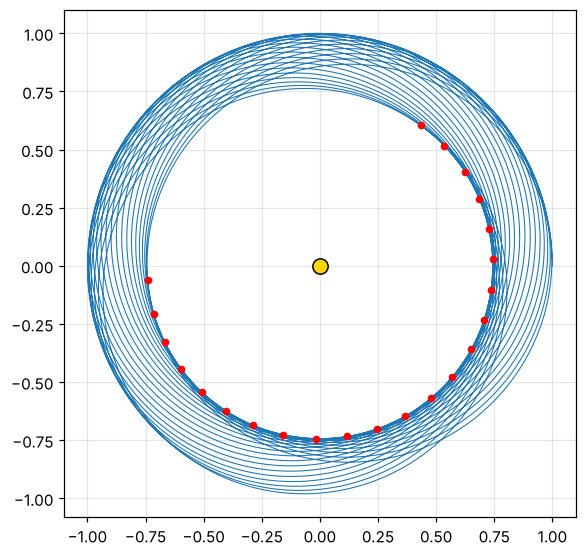

measured advance per orbit: 10.4 deg;  first-order estimate pi*delta/l^2: 10.0 deg


In [5]:
#| label: fig-precession
#| caption: An orbit with a small added 1/r³ attraction (δ = 0.05 in units with γ = μ = 1). Each loop is nearly the Kepler ellipse, but the closest approach advances by about π δ/ℓ² each time (here ℓ ≈ 0.95).
gam, delta = 1.0, 0.05
def rhs(s, y):
    x, yy, vx, vy = y
    r = np.hypot(x, yy)
    a = -(gam / r**2 + delta / r**3) / r
    return [vx, vy, a * x, a * yy]
sol = solve_ivp(rhs, (0, 120), [1, 0, 0, 0.95], max_step=0.01, rtol=1e-10, atol=1e-12)
x, y = sol.y[0], sol.y[1]
r = np.hypot(x, y)
peri = [i for i in range(1, len(r) - 1) if r[i] < r[i - 1] and r[i] < r[i + 1]]
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(x, y, lw=0.7)
ax.plot(x[peri], y[peri], "r.", ms=8)
ax.plot(0, 0, "o", color="gold", ms=10, mec="k"); ax.set_aspect("equal")
plt.show()
angles = np.degrees(np.unwrap(np.arctan2(y[peri], x[peri])))
l = 0.95
print(f"measured advance per orbit: {np.mean(np.diff(angles)):.1f} deg;  first-order estimate pi*delta/l^2: {np.degrees(np.pi * delta / l**2):.1f} deg")

## Gravity of Extended Bodies

A planet is not a point. The **shell theorem** says it can be treated as one: a uniform spherical shell attracts an outside mass as if all its mass were at the center, and exerts no net force on anything inside. For a shell of mass $M$, radius $R$, and a test point at distance $r$ from the center, summing the potential over rings (an M2 integral) gives

$$
\Phi(r) = -G\int\frac{dm}{|\vec{r} - \vec{r}'|} = \begin{cases} -GM/r & r > R \\ -GM/R & r < R\end{cases}
$$

Outside, the potential is that of a point mass; inside, it is constant, so the force vanishes. Any spherically symmetric body is a nest of such shells, so it also acts as a point mass from outside. (Gauss's law for gravity proves the same result in two lines, using the divergence theorem from the vector calculus notes.)

In [6]:
# Shell theorem by direct integration over a uniform shell
G, M, R, r, th = sp.symbols("G M R r theta", positive=True)
sigma = M / (4 * sp.pi * R**2)
dist = sp.sqrt(r**2 + R**2 - 2 * r * R * sp.cos(th))
integrand = -G * sigma * 2 * sp.pi * R**2 * sp.sin(th) / dist        # ring at polar angle theta
Phi = sp.integrate(integrand, (th, 0, sp.pi))
display(Math(r"\text{outside: } \Phi(2R) = " + sp.latex(sp.simplify(Phi.subs(r, 2 * R))) + r"\qquad \text{point-mass value: } " + sp.latex(-G * M / (2 * R))))
display(Math(r"\text{inside: } \Phi(R/2) = " + sp.latex(sp.simplify(Phi.subs(r, R / 2))) + r"\qquad \text{constant value: } " + sp.latex(-G * M / R)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Exercises

1. Use {eq}`eq-vis-viva` to show that a satellite in a circular orbit that fires its engine to speed up ends up on an ellipse with the burn point as perigee.
2. How does the period of a planet change if its orbit's semi-major axis doubles?
3. A tunnel is drilled straight through a uniform-density Earth. Show that an object dropped in it oscillates harmonically, and find the period.

:::{dropdown} Hints
1. Faster than circular speed at $r$ means $1/a < 1/r$.
2. Use {eq}`eq-kepler3`.
3. By the shell theorem only the mass inside radius $r$ pulls, and it scales as $r^3$.
:::

:::{dropdown} Answers
1. $v^2 > GM/r$ gives $a > r$, so the burn point is the closest point of the new ellipse.
2. It grows by $2^{3/2}\approx2.83$.
3. The force is $-GM(r/R)^3m/r^2 = -(GMm/R^3)r$, a spring, so $\tau = 2\pi\sqrt{R^3/GM}\approx84$ minutes, the same as a grazing circular orbit.
:::

## Summary

- Two bodies reduce to one particle of mass $\mu$ plus a uniformly moving center of mass.
- With $u = 1/r$ and $\phi$ as the variable, the orbit equation {eq}`eq-orbit` is linear for gravity, giving conic sections with the force center at a focus.
- Energy sets the eccentricity and the semi-major axis; $\tau^2\propto a^3/(m_1 + m_2)$.
- Vis-viva gives the speed anywhere on an orbit, which is all you need to plan orbit changes such as Hohmann transfers.
- Small deviations from the inverse-square law make orbits precess.
- Spherically symmetric bodies attract like point masses from outside, and exert no net force inside a shell.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.